# Pareto front evolution (batch-by-batch) with polygon enclosure

- Objectives are **maximized**:
  - `separation_coefficient` (higher is better)
  - `lsv_overpotential_-0.01` (treated as "voltage"; higher / less negative is better)

- Samples are grouped into batches of 4 by index (`0–3` = batch 1, `4–7` = batch 2, ...).
- Reference point for enclosure is the **dataset minima** of both objectives (used for geometry; not plotted).
- For each cumulative batch, we draw:
  - Pareto front line
  - A single **polygon enclosure** linked between the reference and the Pareto front
  - A boundary line wrapping the polygon

Styling:
- Rainbow colormap
- Area alpha = **0.05**
- Line alpha = **0.5**


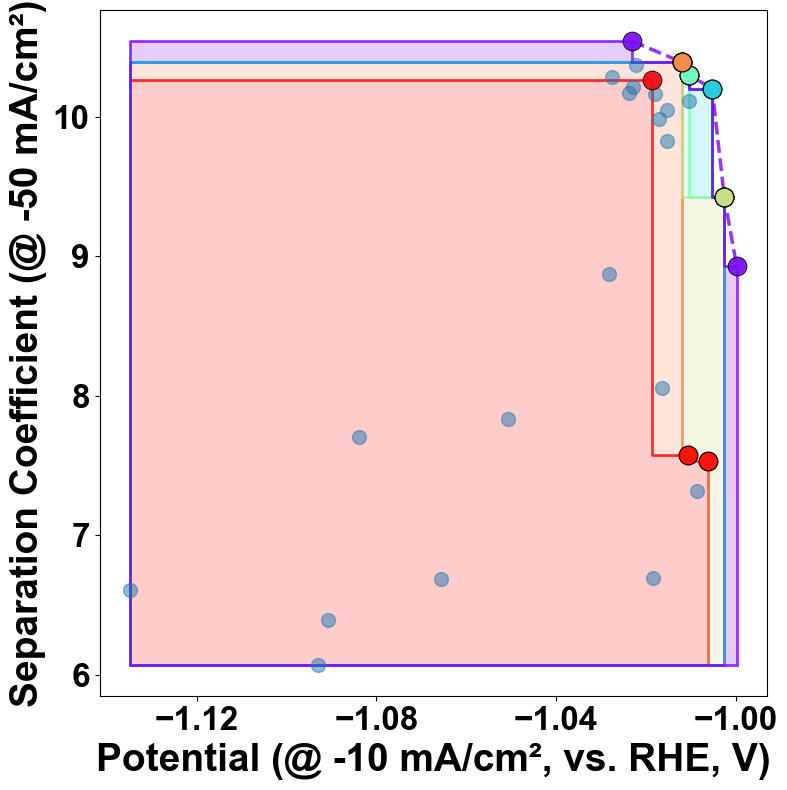

Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\0-Figures\Figure4\1-data\initial_sampling_Co_Mo.png
Reference point used (not plotted): x_ref=-1.134844, y_ref=6.068641
Final hypervolume area: 0.593030
Picked iloc rows: [3, 7, 8, 12, 16, 20, 24, 28]
Mean ± 1 std:
  x: -1.015789 ± 0.006851
  y: 10.243731 ± 0.080271


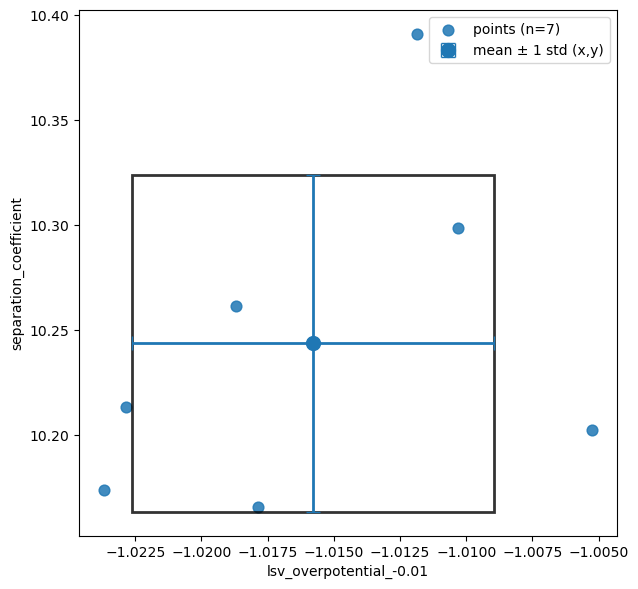

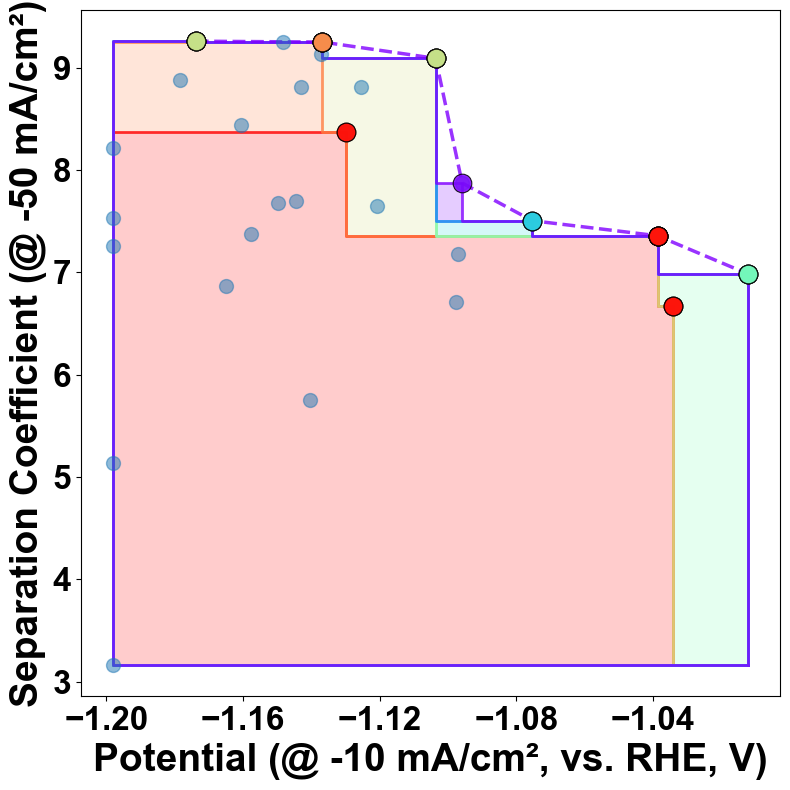

Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\0-Figures\Figure4\1-data\initial_sampling_Co_Ni.png
Reference point used (not plotted): x_ref=-1.198136, y_ref=3.159429
Final hypervolume area: 0.952174
Picked iloc rows: [3, 7, 8, 12, 16, 20, 24, 28]
Mean ± 1 std:
  x: -1.153628 ± 0.018828
  y: 8.653879 ± 0.847528


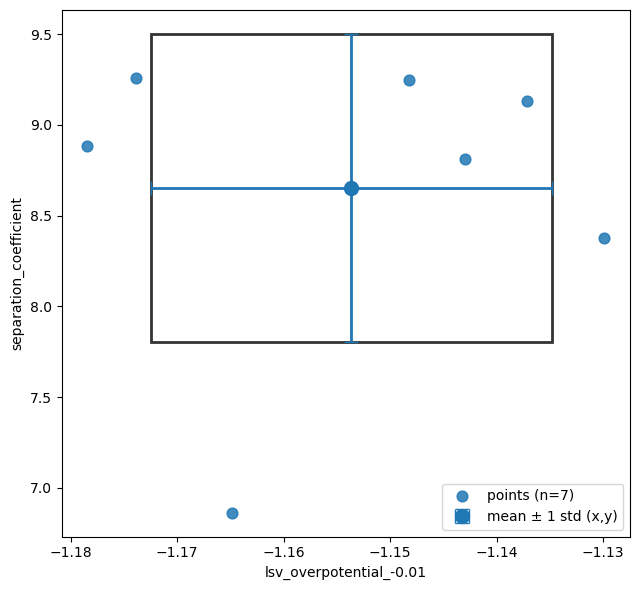

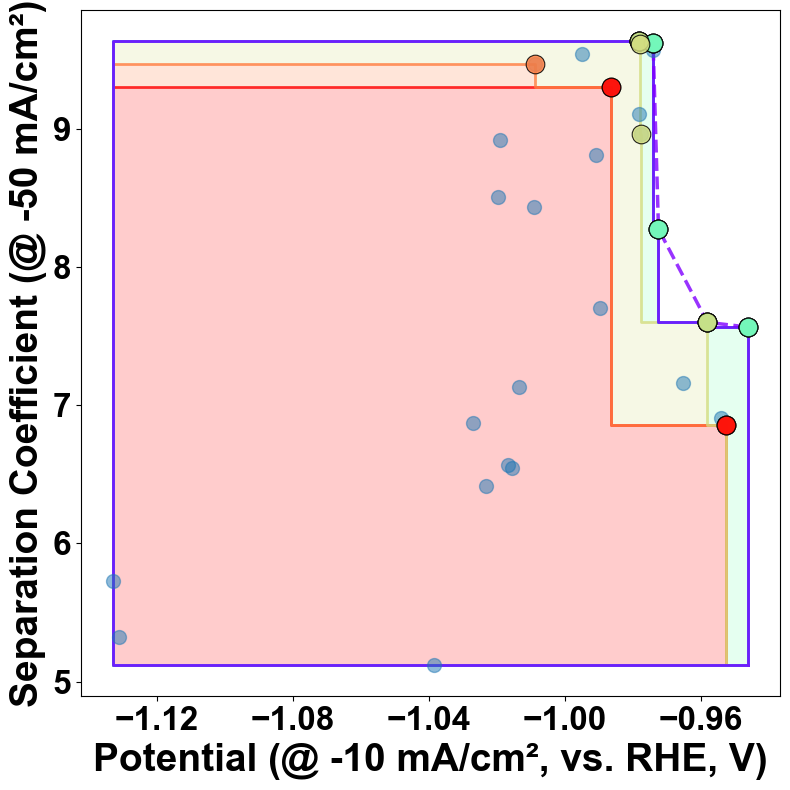

Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\0-Figures\Figure4\1-data\initial_sampling_Co_V.png
Reference point used (not plotted): x_ref=-1.133072, y_ref=5.118585
Final hypervolume area: 0.787859
Picked iloc rows: [3, 7, 8, 12, 16, 20, 24, 28]
Mean ± 1 std:
  x: -0.986401 ± 0.016245
  y: 9.380713 ± 0.278389


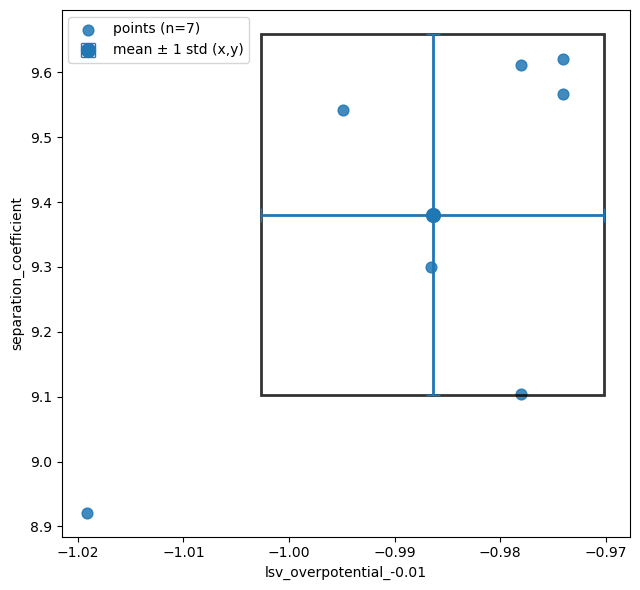

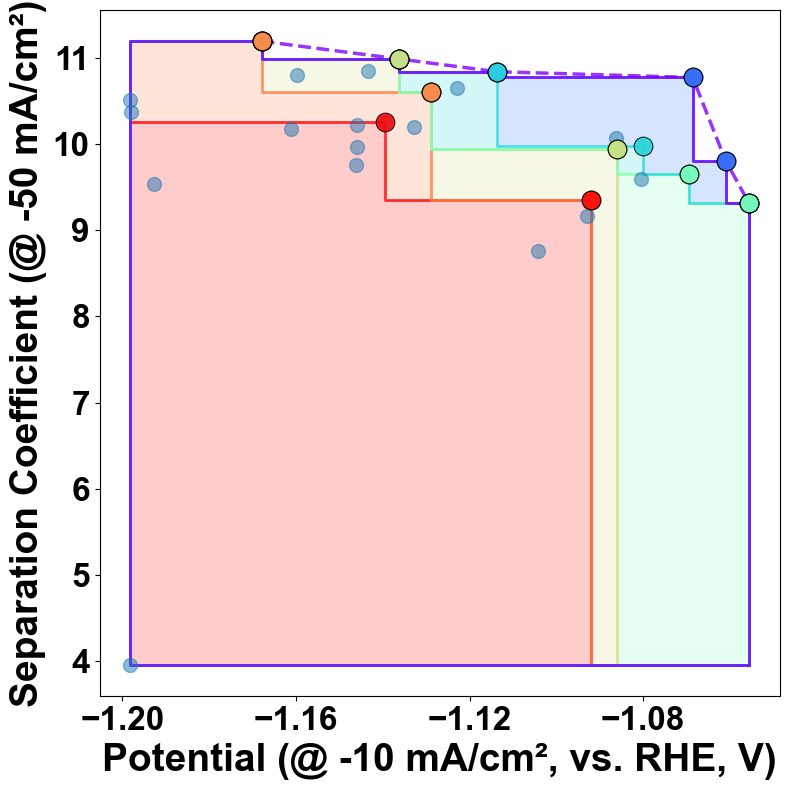

Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\0-Figures\Figure4\1-data\initial_sampling_Fe_Ni.png
Reference point used (not plotted): x_ref=-1.198136, y_ref=3.950333
Final hypervolume area: 0.978716
Picked iloc rows: [3, 7, 8, 12, 16, 20, 24, 28]
Mean ± 1 std:
  x: -1.151954 ± 0.010797
  y: 10.465157 ± 0.496801


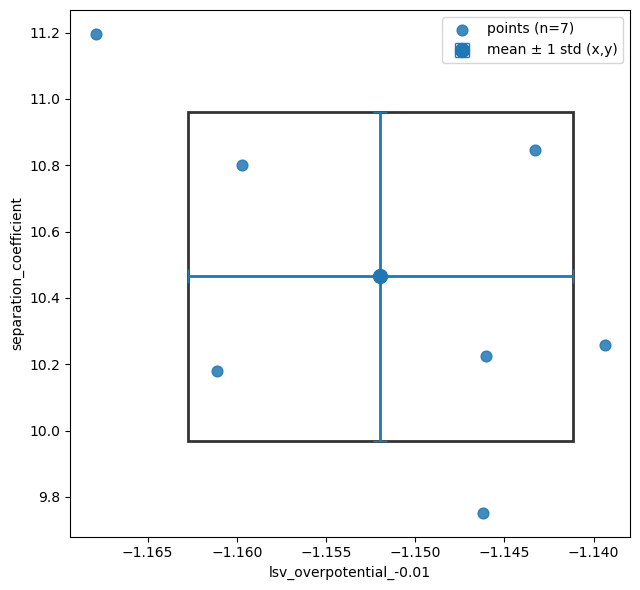

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from shapely.geometry import Polygon, box, MultiPolygon, GeometryCollection
from shapely.ops import unary_union

# =========================
# ---- Input / Settings ----
# =========================
for json_path in [Path("initial_sampling_Co_Mo.json"), Path("initial_sampling_Co_Ni.json"), Path("initial_sampling_Co_V.json"), Path("initial_sampling_Fe_Ni.json")]:
    voltage_key = "lsv_overpotential_-0.01"
    sep_key = "separation_coefficient"

    FIGSIZE = (8, 8)
    S_SCATTER = 100
    SCATTER_ALPHA = 0.50

    AREA_ALPHA = 0.20         # Δ新增区域透明度

    HV_LINE_ALPHA_EARLY = 0.80
    HV_LINE_ALPHA_LAST  = 0.80
    HV_LINE_LW = 2.0

    # 只在最后一波画 Pareto front 线
    PARETO_LINE_ALPHA_LAST = 0.80
    PARETO_LINE_LW = 2.5
    PARETO_MARKERSIZE = 10*2

    # 每一波 Pareto 点（只上色）
    PARETO_POINT_SIZE = 90*2
    PARETO_POINT_ALPHA = 0.85

    REVERSE_RAINBOW = True

    # =========================
    # ---- Load / DataFrame ----
    # =========================
    data = json.loads(json_path.read_text())

    def dictcol_to_series(d):
        s = pd.Series(d)
        s.index = s.index.astype(int)
        return s.sort_index()

    df = pd.DataFrame({
        "id": dictcol_to_series(data[voltage_key]).index,
        "voltage": dictcol_to_series(data[voltage_key]).values,
        "separation": dictcol_to_series(data[sep_key]).values,
    }).dropna(subset=["voltage", "separation"]).reset_index(drop=True)

    df["id"] = df["id"].astype(int)
    df = df.sort_values("id").reset_index(drop=True)

    df["batch"] = (df["id"] // 4) + 1
    max_batch = int(df["batch"].max())

    # Reference point = dataset minima (used for HV; not plotted)
    x_ref = float(df["voltage"].min())
    y_ref = float(df["separation"].min())

    # =========================
    # ---- Pareto front (maximize both) ----
    # =========================
    def pareto_front_max(df_in: pd.DataFrame, x="voltage", y="separation"):
        s = df_in.sort_values([x, y], ascending=[False, False]).reset_index(drop=True)
        best_y = -np.inf
        keep = []
        for _, r in s.iterrows():
            if r[y] > best_y + 1e-12:
                keep.append(True)
                best_y = r[y]
            else:
                keep.append(False)
        front = s.loc[keep].copy()
        return front.sort_values(x, ascending=True).reset_index(drop=True)

    # =========================
    # ---- Shapely helpers ----
    # =========================
    def fix_geom(g):
        if g is None:
            return Polygon()
        if not g.is_valid:
            g = g.buffer(0)
        return g

    def iter_polygons(g):
        if g is None or g.is_empty:
            return
        gt = g.geom_type
        if gt == "Polygon":
            yield g
        elif gt == "MultiPolygon":
            yield from g.geoms
        elif gt == "GeometryCollection":
            for gg in g.geoms:
                yield from iter_polygons(gg)

    def draw_geom_boundary(ax, geom, color, alpha=0.3, lw=2.0):
        for p in iter_polygons(geom):
            x, y = p.exterior.xy
            ax.plot(x, y, color=color, alpha=alpha, linewidth=lw)

    def fill_geom(ax, geom, color, alpha=0.05):
        for p in iter_polygons(geom):
            x, y = p.exterior.xy
            ax.fill(x, y, color=color, alpha=alpha, linewidth=0)

    # =========================
    # ---- Hypervolume region (2D) ----
    # =========================
    def hv_union_geom(front: pd.DataFrame, x_ref: float, y_ref: float,
                    x="voltage", y="separation"):
        rects = []
        for _, r in front.iterrows():
            xi = float(r[x]); yi = float(r[y])
            if xi <= x_ref or yi <= y_ref:
                continue
            rects.append(box(x_ref, y_ref, xi, yi))
        if not rects:
            return Polygon()
        return fix_geom(unary_union(rects))

    # =========================
    # ---- Build cumulative fronts + HV ----
    # =========================
    fronts = {}
    hv_geoms = {}
    for b in range(1, max_batch + 1):
        cum = df[df["batch"] <= b].copy()
        fronts[b] = pareto_front_max(cum)
        hv_geoms[b] = hv_union_geom(fronts[b], x_ref, y_ref)

    # =========================
    # ---- Plot ----
    # =========================
    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.scatter(df["voltage"], df["separation"], s=S_SCATTER, alpha=SCATTER_ALPHA, label="All Samples", zorder = 10)

    # Colors
    cmap = plt.cm.rainbow
    colors = [cmap(i / max(1, (max_batch - 1))) for i in range(max_batch)]
    if REVERSE_RAINBOW:
        colors = colors[::-1]

    # 1) Δ新增 hypervolume 填充（避免重叠糊）
    covered = fix_geom(Polygon())
    for b in range(1, max_batch + 1):
        c = colors[b-1]
        hv_b = hv_geoms[b]
        delta = fix_geom(hv_b.difference(covered))
        covered = fix_geom(unary_union([covered, hv_b]))
        fill_geom(ax, delta, c, alpha=AREA_ALPHA)

    # 2) 前几波：只画 HV 边界线（淡）
    for b in range(1, max_batch):
        c = colors[b-1]
        draw_geom_boundary(ax, hv_geoms[b], c, alpha=HV_LINE_ALPHA_EARLY, lw=HV_LINE_LW)

    # 3) 最后一波：画 HV 边界线（强调）
    last_color = colors[max_batch - 1]
    draw_geom_boundary(ax, hv_geoms[max_batch], last_color, alpha=HV_LINE_ALPHA_LAST, lw=HV_LINE_LW)

    # 4) 每一波：把 Pareto front 的点画出来（只给点颜色，不画线）
    for b in range(1, max_batch + 1):
        f = fronts[b]
        c = colors[b-1]
        ax.scatter(
            f["voltage"], f["separation"],
            s=PARETO_POINT_SIZE,
            color=c,
            edgecolors="black",
            linewidths=0.8,      # ✅ 这里
            alpha=PARETO_POINT_ALPHA,
            zorder=100 - b,
            label=f"Batch {b}"
        )
        #  # 虚线连接（dashed）
        # ax.plot(
        #     f["voltage"], f["separation"],
        #     linestyle="--",
        #     linewidth=1.5,
        #     color=c,
        #     alpha=0.6,
        #     zorder=99 - b
        # )

    # 5) 仅最后一波：画 Pareto front 线
    f_last = fronts[max_batch]
    ax.plot(
        f_last["voltage"], f_last["separation"],
        linewidth=PARETO_LINE_LW,
        markersize=PARETO_MARKERSIZE,
        color=last_color,
        alpha=PARETO_LINE_ALPHA_LAST,
        label=f"Pareto Front",
        linestyle="--",
    )

    # ---- axis formatting (沿用你之前风格) ----
    from matplotlib.ticker import MultipleLocator
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_major_locator(MultipleLocator(0.04))

    ax.tick_params(axis="both", which="both", labelsize=24)
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_fontname("Arial")
        t.set_fontweight("bold")

    ax.set_ylabel("Separation Coefficient (@ -50 mA/cm²)", fontname="Arial", fontweight="bold", fontsize=28)
    ax.set_xlabel("Potential (@ -10 mA/cm², vs. RHE, V)", fontname="Arial", fontweight="bold", fontsize=28)

    plt.tight_layout()
    plt.show()

    out_png = Path(str(json_path).replace(".json", ".png"))
    fig.savefig(out_png, dpi=600)
    print("Saved:", out_png.resolve())
    print(f"Reference point used (not plotted): x_ref={x_ref:.6f}, y_ref={y_ref:.6f}")
    print(f"Final hypervolume area: {hv_geoms[max_batch].area:.6f}")

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle

    features = ["lsv_overpotential_-0.01", "separation_coefficient"]
    data = pd.DataFrame(data).copy()

    # ---- build indices: 3, 7, 8, 12, 16, 20, ...
    idx = [3, 7, 8] + list(range(12, len(data), 4))
    idx = [i for i in idx if 0 <= i < len(data)]  # safe guard

    pts = data.iloc[idx][features].apply(pd.to_numeric, errors="coerce").dropna(how="any")

    x = pts[features[0]].to_numpy()
    y = pts[features[1]].to_numpy()

    mean_x, mean_y = np.mean(x), np.mean(y)
    std_x  = np.std(x, ddof=1) if len(x) > 1 else np.nan
    std_y  = np.std(y, ddof=1) if len(y) > 1 else np.nan

    plt.figure(figsize=(6.5, 6.0))
    plt.scatter(x, y, s=60, alpha=0.85, label=f"points (n={len(pts)})")

    plt.errorbar(
        mean_x, mean_y,
        xerr=std_x if np.isfinite(std_x) else None,
        yerr=std_y if np.isfinite(std_y) else None,
        fmt="o", markersize=10, capsize=5, linewidth=2,
        label="mean ± 1 std (x,y)"
    )

    print(f"Picked iloc rows: {idx}")
    print(f"Mean ± 1 std:\n  x: {mean_x:.6f} ± {std_x:.6f}\n  y: {mean_y:.6f} ± {std_y:.6f}")

    if np.isfinite(std_x) and np.isfinite(std_y):
        rect = Rectangle((mean_x - std_x, mean_y - std_y),
                        2*std_x, 2*std_y,
                        fill=False, linewidth=2, alpha=0.8)
        plt.gca().add_patch(rect)

    plt.xlabel(features[0])
    plt.ylabel(features[1])
    plt.legend()
    plt.tight_layout()
    plt.show()

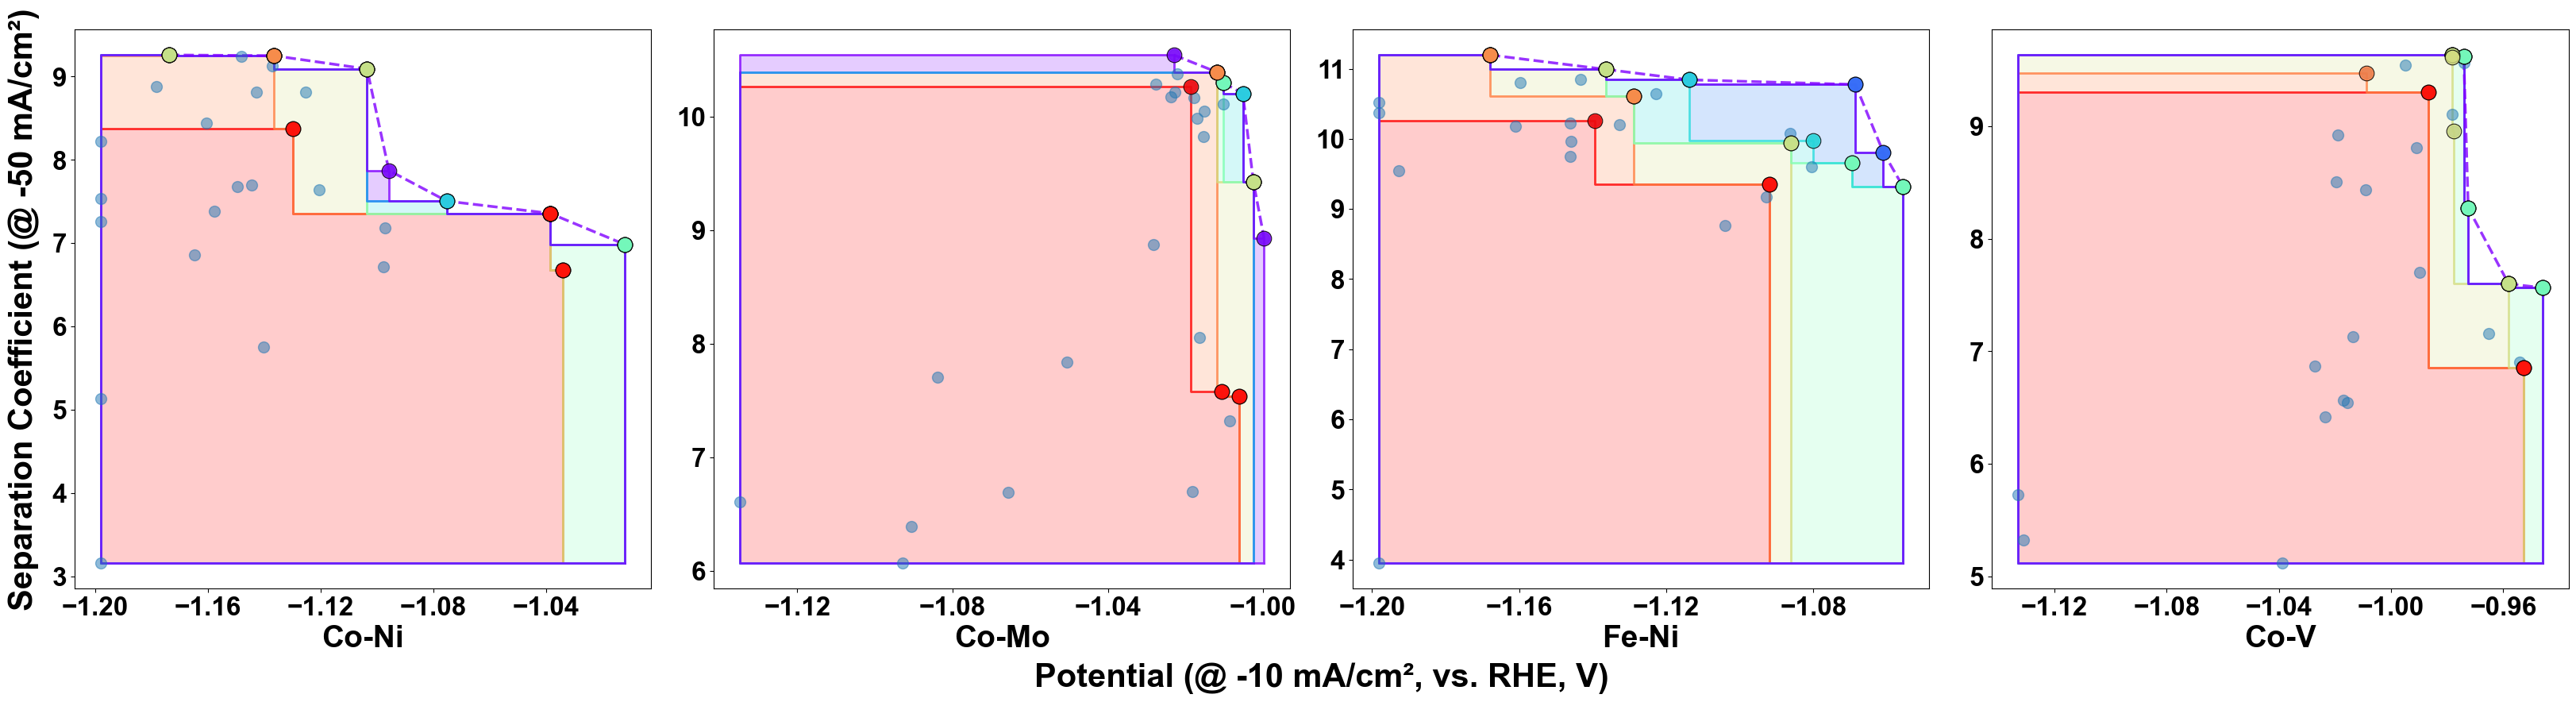

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import Polygon, box, MultiPolygon, GeometryCollection
from shapely.ops import unary_union

# -------------------------
# your existing settings
# -------------------------
voltage_key = "lsv_overpotential_-0.01"
sep_key     = "separation_coefficient"

FIGSIZE = (8, 8)
S_SCATTER = 100
SCATTER_ALPHA = 0.50
AREA_ALPHA = 0.20
HV_LINE_ALPHA_EARLY = 0.80
HV_LINE_ALPHA_LAST  = 0.80
HV_LINE_LW = 2.0
PARETO_LINE_ALPHA_LAST = 0.80
PARETO_LINE_LW = 2.5
PARETO_MARKERSIZE = 10*2
PARETO_POINT_SIZE = 90*2
PARETO_POINT_ALPHA = 0.85
REVERSE_RAINBOW = True

# -------------------------
# helpers (unchanged)
# -------------------------
def dictcol_to_series(d):
    s = pd.Series(d)
    s.index = s.index.astype(int)
    return s.sort_index()

def pareto_front_max(df_in: pd.DataFrame, x="voltage", y="separation"):
    s = df_in.sort_values([x, y], ascending=[False, False]).reset_index(drop=True)
    best_y = -np.inf
    keep = []
    for _, r in s.iterrows():
        if r[y] > best_y + 1e-12:
            keep.append(True)
            best_y = r[y]
        else:
            keep.append(False)
    front = s.loc[keep].copy()
    return front.sort_values(x, ascending=True).reset_index(drop=True)

def fix_geom(g):
    if g is None:
        return Polygon()
    if not g.is_valid:
        g = g.buffer(0)
    return g

def iter_polygons(g):
    if g is None or g.is_empty:
        return
    gt = g.geom_type
    if gt == "Polygon":
        yield g
    elif gt == "MultiPolygon":
        yield from g.geoms
    elif gt == "GeometryCollection":
        for gg in g.geoms:
            yield from iter_polygons(gg)

def draw_geom_boundary(ax, geom, color, alpha=0.3, lw=2.0):
    for p in iter_polygons(geom):
        x, y = p.exterior.xy
        ax.plot(x, y, color=color, alpha=alpha, linewidth=lw)

def fill_geom(ax, geom, color, alpha=0.05):
    for p in iter_polygons(geom):
        x, y = p.exterior.xy
        ax.fill(x, y, color=color, alpha=alpha, linewidth=0)

def hv_union_geom(front: pd.DataFrame, x_ref: float, y_ref: float,
                  x="voltage", y="separation"):
    rects = []
    for _, r in front.iterrows():
        xi = float(r[x]); yi = float(r[y])
        if xi <= x_ref or yi <= y_ref:
            continue
        rects.append(box(x_ref, y_ref, xi, yi))
    if not rects:
        return Polygon()
    return fix_geom(unary_union(rects))

# -------------------------
# plot-one-panel function
# -------------------------
def plot_system(ax, json_path: Path):
    data = json.loads(json_path.read_text())

    df = pd.DataFrame({
        "id": dictcol_to_series(data[voltage_key]).index,
        "voltage": dictcol_to_series(data[voltage_key]).values,
        "separation": dictcol_to_series(data[sep_key]).values,
    }).dropna(subset=["voltage", "separation"]).reset_index(drop=True)

    df["id"] = df["id"].astype(int)
    df = df.sort_values("id").reset_index(drop=True)
    df["batch"] = (df["id"] // 4) + 1
    max_batch = int(df["batch"].max())

    x_ref = float(df["voltage"].min())
    y_ref = float(df["separation"].min())

    fronts, hv_geoms = {}, {}
    for b in range(1, max_batch + 1):
        cum = df[df["batch"] <= b].copy()
        fronts[b] = pareto_front_max(cum)
        hv_geoms[b] = hv_union_geom(fronts[b], x_ref, y_ref)

    # ---- plot (same as before, but on ax) ----
    ax.scatter(df["voltage"], df["separation"],
               s=S_SCATTER, alpha=SCATTER_ALPHA, zorder=10)

    cmap = plt.cm.rainbow
    colors = [cmap(i / max(1, (max_batch - 1))) for i in range(max_batch)]
    if REVERSE_RAINBOW:
        colors = colors[::-1]

    covered = fix_geom(Polygon())
    for b in range(1, max_batch + 1):
        c = colors[b-1]
        hv_b = hv_geoms[b]
        delta = fix_geom(hv_b.difference(covered))
        covered = fix_geom(unary_union([covered, hv_b]))
        fill_geom(ax, delta, c, alpha=AREA_ALPHA)

    for b in range(1, max_batch):
        c = colors[b-1]
        draw_geom_boundary(ax, hv_geoms[b], c, alpha=HV_LINE_ALPHA_EARLY, lw=HV_LINE_LW)

    last_color = colors[max_batch - 1]
    draw_geom_boundary(ax, hv_geoms[max_batch], last_color, alpha=HV_LINE_ALPHA_LAST, lw=HV_LINE_LW)

    for b in range(1, max_batch + 1):
        f = fronts[b]
        c = colors[b-1]
        ax.scatter(f["voltage"], f["separation"],
                   s=PARETO_POINT_SIZE, color=c,
                   edgecolors="black", linewidths=0.8,
                   alpha=PARETO_POINT_ALPHA, zorder=100 - b)

    f_last = fronts[max_batch]
    ax.plot(f_last["voltage"], f_last["separation"],
            linewidth=PARETO_LINE_LW, markersize=PARETO_MARKERSIZE,
            color=last_color, alpha=PARETO_LINE_ALPHA_LAST,
            linestyle="--")

    # tick styling (same)
    from matplotlib.ticker import MultipleLocator
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_major_locator(MultipleLocator(0.04))
    ax.tick_params(axis="both", which="both", labelsize=24)
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_fontname("Arial")
        t.set_fontweight("bold")

# -------------------------
# 1×4 layout + shared labels
# -------------------------
systems = [
    (Path("initial_sampling_Co_Ni.json"), "Co-Ni"),
    (Path("initial_sampling_Co_Mo.json"), "Co-Mo"),
    (Path("initial_sampling_Fe_Ni.json"), "Fe-Ni"),
    (Path("initial_sampling_Co_V.json"),  "Co-V"),
]

fig, axs = plt.subplots(
    1, len(systems),
    figsize=(FIGSIZE[0]*len(systems), FIGSIZE[1])  # keep each panel ~8×8
)

for ax, (p, sys_name) in zip(axs, systems):
    plot_system(ax, p)

    # system name on each panel's x-axis (middle)
    ax.set_xlabel(sys_name, fontname="Arial", fontweight="bold", fontsize=28)

    # remove per-panel y label (shared below)
    ax.set_ylabel("")

# # shared X/Y labels (not ticks)
# fig.supxlabel("Potential (@ -10 mA/cm², vs. RHE, V)",
#               fontname="Arial", fontweight="bold", fontsize=30)
# fig.supylabel("Separation Coefficient (@ -50 mA/cm²)",
#               fontname="Arial", fontweight="bold", fontsize=30)

# leave room for the shared labels (so they don't collide)
fig.tight_layout(rect=[0.04, 0.02, 1.04, 1.04])

import matplotlib.transforms as mtransforms
# Compute the bounding box of the subplot area (in figure coords)
bbox = mtransforms.Bbox.union([ax.get_position() for ax in axs])
y_center = 0.5 * (bbox.y0 + bbox.y1)
x_center = 0.5 * (bbox.x0 + bbox.x1)

x_left   = bbox.x0

# Remove any previous supylabel if you used it
# (just don't call fig.supylabel earlier)

# Place shared Y label centered to the subplot block
pad = 0.02  # tweak if you want it closer/farther
fig.text(
    x_left - pad, y_center,
    "Separation Coefficient (@ -50 mA/cm²)",
    rotation="vertical",
    va="center", ha="center",
    fontname="Arial", fontweight="bold", fontsize=30
)

fig.text(
    x_center, 0,
    "Potential (@ -10 mA/cm², vs. RHE, V)",
    va="center", ha="center",
    fontname="Arial", fontweight="bold", fontsize=30
)

plt.show()
fig.savefig("four_systems_row.png", dpi=600, bbox_inches="tight", pad_inches=0.02)

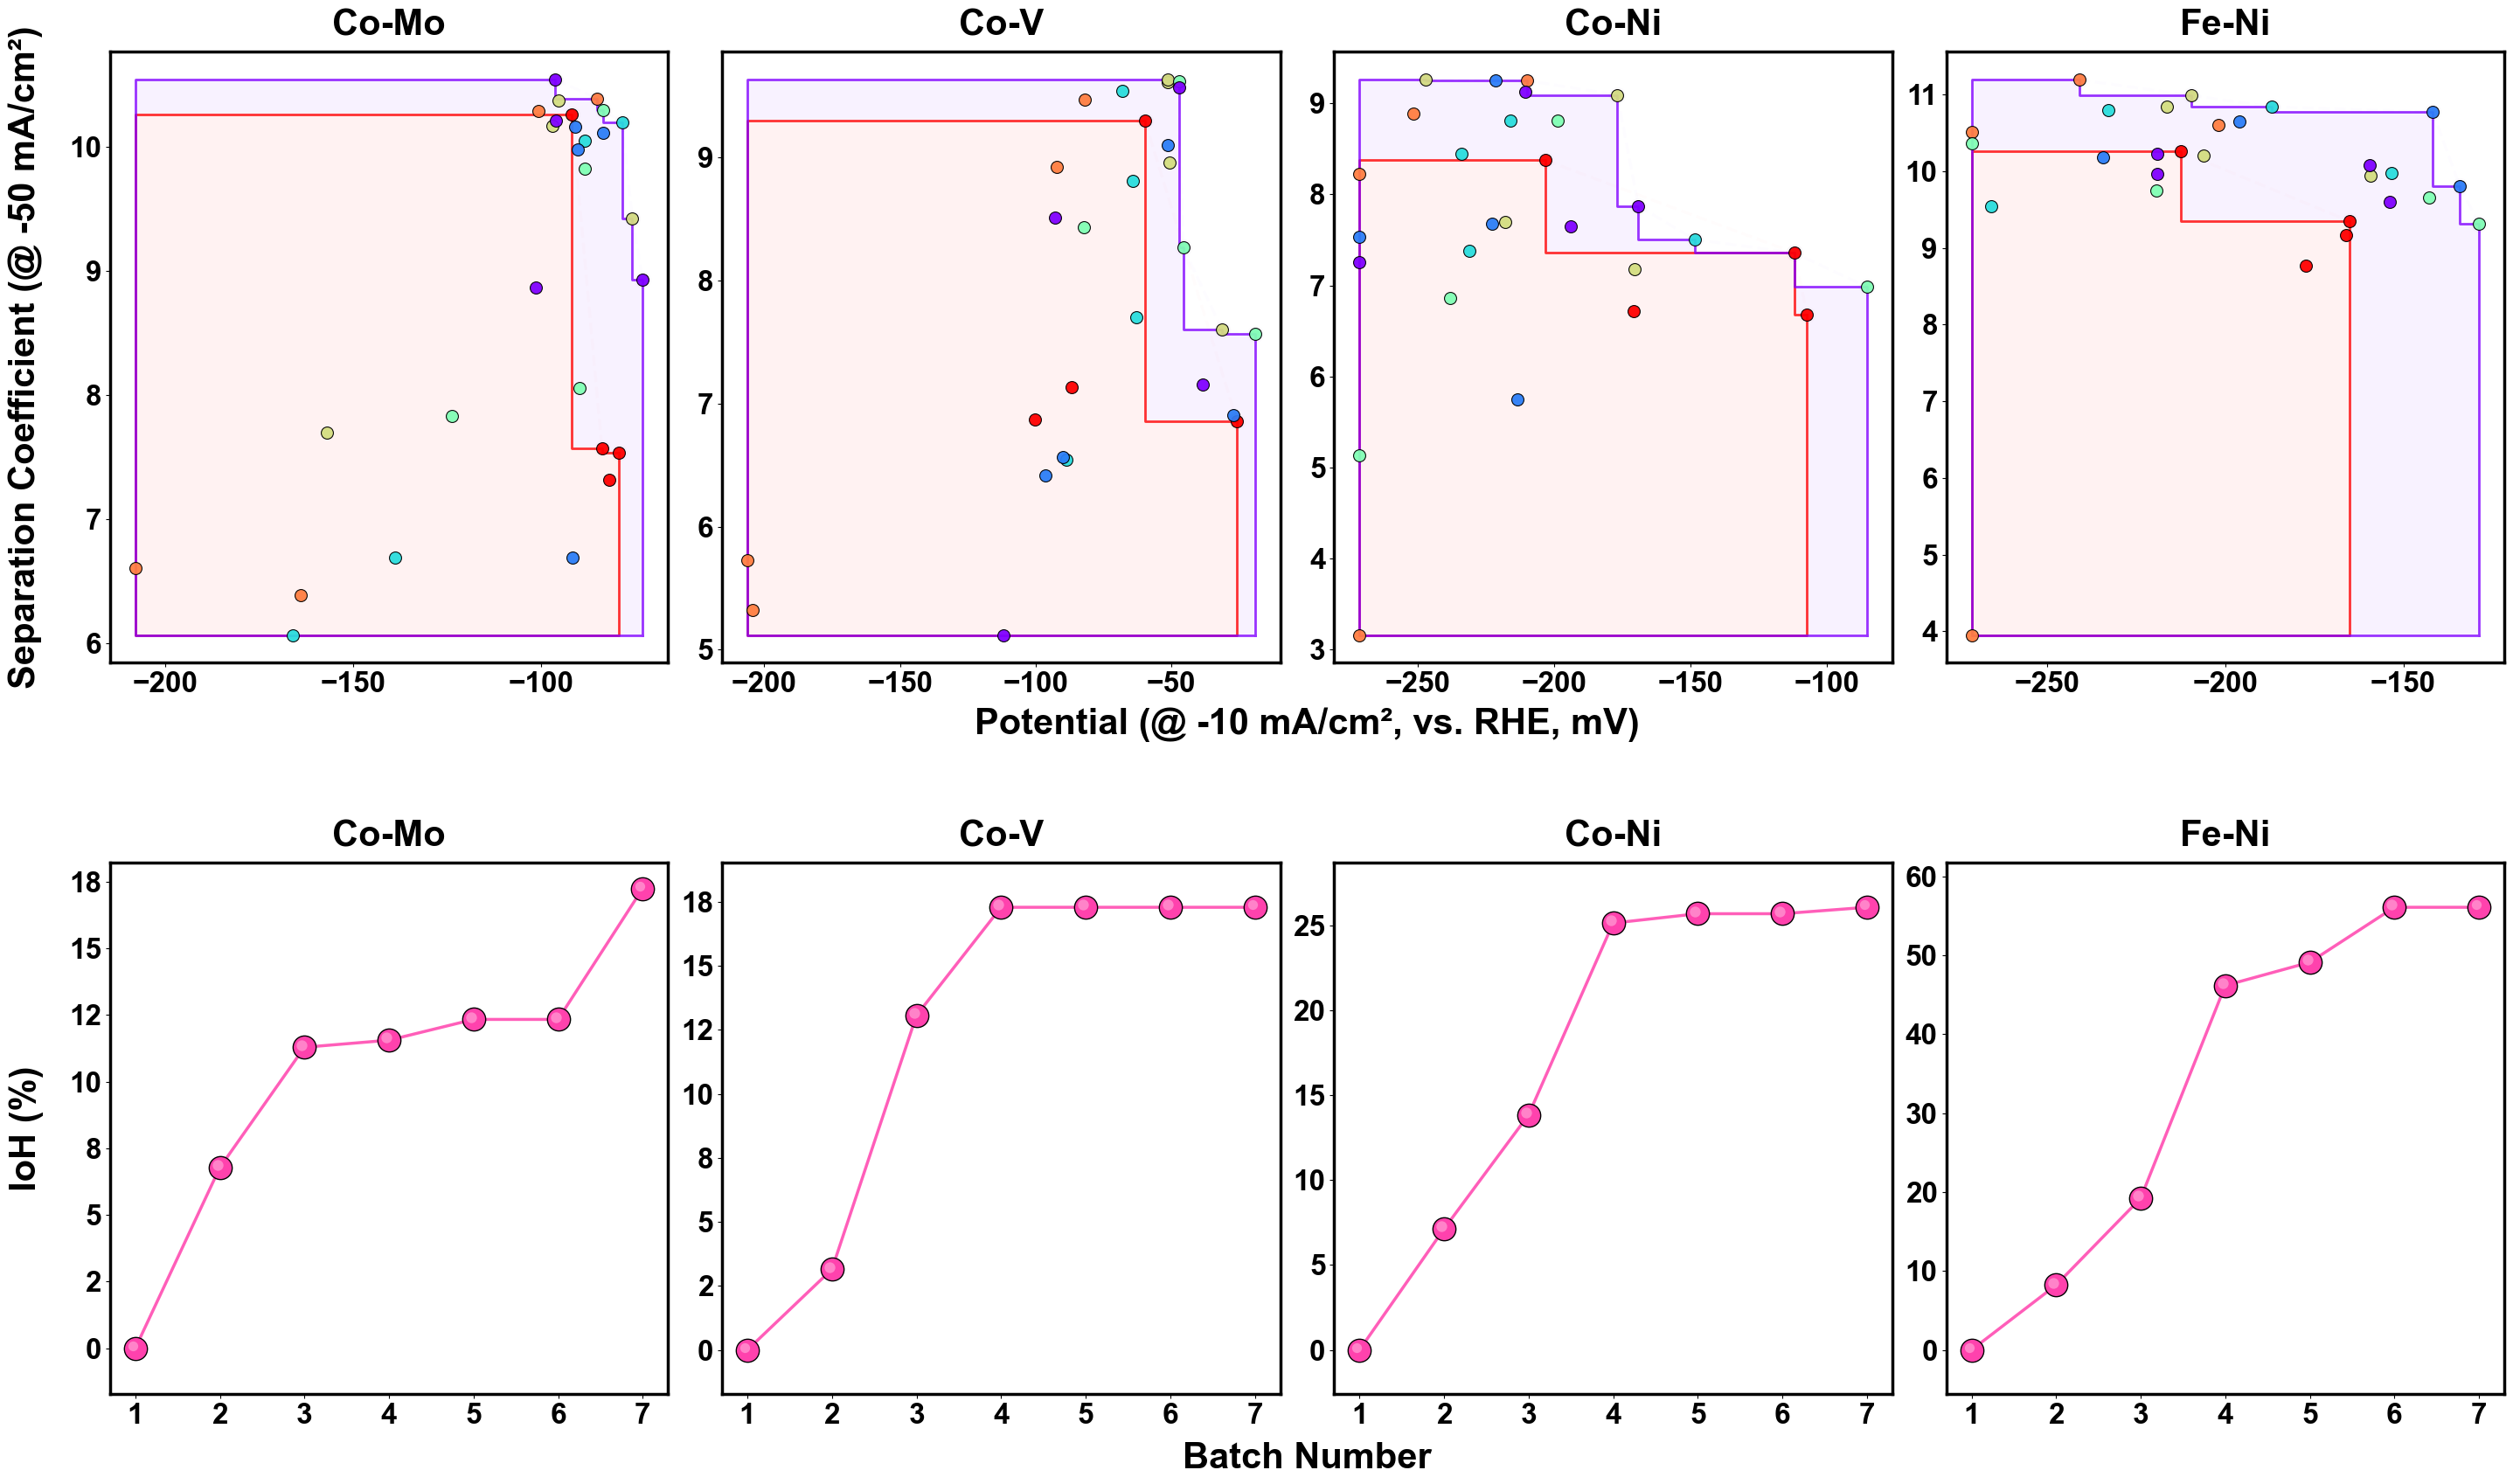

In [5]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import Polygon, box
from shapely.ops import unary_union
import matplotlib.transforms as mtransforms
from matplotlib.ticker import FuncFormatter

# -------------------------
# keys
# -------------------------
voltage_key = "lsv_overpotential_-0.01"
sep_key     = "separation_coefficient"

# -------------------------
# systems (4 columns)
# -------------------------
systems = [
    (Path("initial_sampling_Co_Mo.json"), "Co-Mo"),
    (Path("initial_sampling_Co_V.json"),  "Co-V"),
    (Path("initial_sampling_Co_Ni.json"), "Co-Ni"),
    (Path("initial_sampling_Fe_Ni.json"), "Fe-Ni"),
]

# -------------------------
# TOP row style (Pareto + HV area)
# -------------------------
TOP_FIGSIZE_PER_PANEL = (8, 9)  # (w,h) per panel in inches
S_SCATTER = 100
SCATTER_ALPHA = 0.95
AREA_ALPHA = 0.05
HV_LINE_ALPHA_EARLY = 0.80
HV_LINE_ALPHA_LAST  = 0.80
HV_LINE_LW = 2.0
PARETO_LINE_ALPHA_LAST = 0.01
PARETO_LINE_LW = 2.5
PARETO_MARKERSIZE = 20
PARETO_POINT_SIZE = 180
PARETO_POINT_ALPHA = 0.01
REVERSE_RAINBOW = True
FRAME_LW = 2.5

# -------------------------
# BOTTOM row style (HV vs batch)
# -------------------------
LINE_LW = 2.5
LINE_ALPHA = 0.85
SCATTER_S = 300
SCATTER_ALPHA = 0.95
HIGHLIGHT_S = 300

# choose what to plot:
#   "gain"       : HV(b) - HV(1)   (starts at 0)
#   "absolute"   : HV(b)
#   "normalized" : (HV(b)-HV(1)) / (HV(last)-HV(1))   (0→1)
HV_MODE = "normalized_to_initial"

# -------------------------
# helpers
# -------------------------
def dictcol_to_series(d):
    s = pd.Series(d)
    s.index = s.index.astype(int)
    return s.sort_index()

def load_system_df(json_path: Path):
    data = json.loads(json_path.read_text())
    
    df = pd.DataFrame({
        "id": dictcol_to_series(data[voltage_key]).index,
        "voltage": 1000*(dictcol_to_series(data[voltage_key]).values + 0.0592*14 + 0.098),
        "separation": dictcol_to_series(data[sep_key]).values,
    }).dropna(subset=["voltage", "separation"]).reset_index(drop=True)

    df["id"] = df["id"].astype(int)
    df = df.sort_values("id").reset_index(drop=True)
    df["batch"] = (df["id"] // 4) + 1
    max_batch = int(df["batch"].max())

    x_ref = float(df["voltage"].min())
    y_ref = float(df["separation"].min())
    return df, max_batch, x_ref, y_ref

def pareto_front_max(df_in: pd.DataFrame, x="voltage", y="separation"):
    s = df_in.sort_values([x, y], ascending=[False, False]).reset_index(drop=True)
    best_y = -np.inf
    keep = []
    for _, r in s.iterrows():
        if r[y] > best_y + 1e-12:
            keep.append(True)
            best_y = r[y]
        else:
            keep.append(False)
    front = s.loc[keep].copy()
    return front.sort_values(x, ascending=True).reset_index(drop=True)

def fix_geom(g):
    if g is None:
        return Polygon()
    if not g.is_valid:
        g = g.buffer(0)
    return g

def iter_polygons(g):
    if g is None or g.is_empty:
        return
    gt = g.geom_type
    if gt == "Polygon":
        yield g
    elif gt == "MultiPolygon":
        yield from g.geoms
    elif gt == "GeometryCollection":
        for gg in g.geoms:
            yield from iter_polygons(gg)

def draw_geom_boundary(ax, geom, color, alpha=0.3, lw=2.0):
    for p in iter_polygons(geom):
        x, y = p.exterior.xy
        ax.plot(x, y, color=color, alpha=alpha, linewidth=lw)

def fill_geom(ax, geom, color, alpha=0.05):
    for p in iter_polygons(geom):
        x, y = p.exterior.xy
        ax.fill(x, y, color=color, alpha=alpha, linewidth=0)

def hv_union_geom(front: pd.DataFrame, x_ref: float, y_ref: float,
                  x="voltage", y="separation"):
    rects = []
    for _, r in front.iterrows():
        xi = float(r[x]); yi = float(r[y])
        if xi <= x_ref or yi <= y_ref:
            continue
        rects.append(box(x_ref, y_ref, xi, yi))
    if not rects:
        return Polygon()
    return fix_geom(unary_union(rects))

def shiny_ball(ax, x, y, s=140, color=None, edgecolor="black", lw=1.0,
               highlight_alpha=0.35, zorder=20):
    if color is None:
        color = plt.rcParams["axes.prop_cycle"].by_key()["color"][0]

    ax.scatter([x], [y], s=s, color=color, edgecolors=edgecolor, linewidths=lw, zorder=zorder)

    fig = ax.figure
    offset = mtransforms.ScaledTranslation(-2/72., 2/72., fig.dpi_scale_trans)
    ax.scatter([x], [y],
               s=s * 0.22,
               color="white",
               alpha=highlight_alpha,
               linewidths=0,
               transform=ax.transData + offset,
               zorder=zorder + 10)

# -------------------------
# TOP row plotting
# -------------------------
def plot_system(ax, json_path: Path):
    df, max_batch, x_ref, y_ref = load_system_df(json_path)
    fronts, hv_geoms = {}, {}
    for b in range(1, max_batch + 1):
        cum = df[df["batch"] <= b].copy()
        fronts[b] = pareto_front_max(cum)
        hv_geoms[b] = hv_union_geom(fronts[b], x_ref, y_ref)

    cmap = plt.cm.rainbow
    colors = [cmap(i / max(1, (max_batch - 1))) for i in range(max_batch)]
    if REVERSE_RAINBOW:
        colors = colors[::-1]

    # scatter all points colored by batch
    for b in range(1, max_batch + 1):
        c = colors[b - 1]
        dfb = df[df["batch"] == b]
        ax.scatter(dfb["voltage"], dfb["separation"],
                   s=S_SCATTER, color=c, alpha=SCATTER_ALPHA, edgecolors="black", linewidths=0.8, zorder=110)

    c1 = colors[0]
    cl = colors[max_batch - 1]

    hv1 = fix_geom(hv_geoms[1])
    hvl = fix_geom(hv_geoms[max_batch])

    fill_geom(ax, hv1, c1, alpha=AREA_ALPHA)
    if max_batch > 1:
        delta_last = fix_geom(hvl.difference(hv1))
        fill_geom(ax, delta_last, cl, alpha=AREA_ALPHA)

    draw_geom_boundary(ax, hv1, c1, alpha=HV_LINE_ALPHA_EARLY, lw=HV_LINE_LW)
    if max_batch > 1:
        draw_geom_boundary(ax, hvl, cl, alpha=HV_LINE_ALPHA_LAST, lw=HV_LINE_LW)

    # Pareto front for batch 1 + last batch
    f1 = fronts[1]
    ax.scatter(f1["voltage"], f1["separation"],
               s=PARETO_POINT_SIZE, color=c1,
               edgecolors="black", linewidths=0.8,
               alpha=PARETO_POINT_ALPHA, zorder=120)
    ax.plot(f1["voltage"], f1["separation"],
            linewidth=PARETO_LINE_LW, markersize=PARETO_MARKERSIZE,
            color=c1, alpha=PARETO_LINE_ALPHA_LAST, linestyle="--")

    f_last = fronts[max_batch]
    ax.scatter(f_last["voltage"], f_last["separation"],
               s=PARETO_POINT_SIZE, color=cl,
               edgecolors="black", linewidths=0.8,
               alpha=PARETO_POINT_ALPHA, zorder=130)
    ax.plot(f_last["voltage"], f_last["separation"],
            linewidth=PARETO_LINE_LW, markersize=PARETO_MARKERSIZE,
            color=cl, alpha=PARETO_LINE_ALPHA_LAST, linestyle="--")

    # ticks + frame
    from matplotlib.ticker import MultipleLocator
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_major_locator(MultipleLocator(50))
    ax.tick_params(axis="both", which="both", labelsize=24)
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_fontname("Arial")
        t.set_fontweight("bold")
    for side in ["left", "right", "top", "bottom"]:
        ax.spines[side].set_linewidth(FRAME_LW)

# -------------------------
# BOTTOM row plotting
# -------------------------
def compute_hv_series(json_path: Path):
    df, max_batch, x_ref, y_ref = load_system_df(json_path)

    hv = []
    batches = np.arange(1, max_batch + 1, dtype=int)
    for b in batches:
        cum = df[df["batch"] <= b].copy()
        front = pareto_front_max(cum)
        hv_geom = hv_union_geom(front, x_ref, y_ref)
        hv.append(float(fix_geom(hv_geom).area))

    hv = np.asarray(hv, dtype=float)

    if HV_MODE == "absolute":
        y = hv
    elif HV_MODE == "gain":
        y = hv - hv[0]
    elif HV_MODE == "normalized":
        denom = (hv[-1] - hv[0])
        y = (hv - hv[0]) / denom if abs(denom) > 1e-12 else np.zeros_like(hv)
    elif HV_MODE == "normalized_to_initial":
        denom = (hv[0])
        y = 100*(hv - hv[0]) / denom if abs(denom) > 1e-12 else np.zeros_like(hv)
    else:
        raise ValueError("HV_MODE must be one of: 'gain', 'absolute', 'normalized'")

    return batches, y, hv

def plot_hv_panel(ax, json_path: Path):
    batches, y, _ = compute_hv_series(json_path)

    main_color = "#FF42AD"

    ax.plot(batches, y, linewidth=LINE_LW, alpha=LINE_ALPHA, color=main_color, zorder=10)

    for b in batches:
        shiny_ball(ax, b, y[b - 1], s=SCATTER_S*1.2, color=main_color, lw=1.0, zorder=20)

    shiny_ball(ax, batches[0],  y[0],  s=HIGHLIGHT_S, color=main_color, lw=0.0, zorder=30)
    shiny_ball(ax, batches[-1], y[-1], s=HIGHLIGHT_S, color=main_color, lw=0.0, zorder=31)

    ax.set_xticks(batches)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:.0f}"))

    ax.tick_params(axis="both", which="both", labelsize=24)
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_fontname("Arial")
        t.set_fontweight("bold")

    ax.margins(x=0.05, y=0.10)
    for side in ["left", "right", "top", "bottom"]:
        ax.spines[side].set_linewidth(FRAME_LW)

# -------------------------
# 2×4 figure
# -------------------------
ncol = len(systems)
fig_w = TOP_FIGSIZE_PER_PANEL[0] * ncol
fig_h = TOP_FIGSIZE_PER_PANEL[1] * 2

fig, axs = plt.subplots(
    2, ncol,
    figsize=(fig_w, fig_h),
    gridspec_kw={"height_ratios": [1.15, 1.00]}
)

# plot each column
for j, (p, sys_name) in enumerate(systems):
    ax_top = axs[0, j]
    ax_bot = axs[1, j]

    plot_system(ax_top, p)
    plot_hv_panel(ax_bot, p)
    if sys_name == "Co-Mo":
        ax_bot.set_ylim(top=18.2)
        
    # title only on the TOP row
    ax_top.set_title(sys_name, fontname="Arial", fontweight="bold", fontsize=30, pad=14)

    # remove top-row axis labels (use shared labels instead)
    ax_top.set_xlabel("")
    ax_top.set_ylabel("")

    # KEEP system name for bottom row (as xlabel)
    ax_bot.set_title(sys_name, fontname="Arial", fontweight="bold", fontsize=30, pad=14)
    ax_bot.set_xlabel("")
    ax_bot.set_ylabel("")


# leave room for shared labels
ROW_HPAD = 10.0  # increase to make the two rows further apart (try 2.0 ~ 5.0)
fig.tight_layout(rect=[0.11, 0.06, 0.99, 0.98], h_pad=ROW_HPAD)

# -------------------------
# shared labels (top row and bottom row separately)
# -------------------------
top_axes = list(axs[0, :].ravel())
bot_axes = list(axs[1, :].ravel())

bbox_top = mtransforms.Bbox.union([ax.get_position() for ax in top_axes])
bbox_bot = mtransforms.Bbox.union([ax.get_position() for ax in bot_axes])

pad = 0.02

# Top row shared labels
y_center_top = 0.5 * (bbox_top.y0 + bbox_top.y1)
x_center_top = 0.5 * (bbox_top.x0 + bbox_top.x1)
x_left_top   = bbox_top.x0

fig.text(
    x_left_top - 1.5*pad, y_center_top,
    "Separation Coefficient (@ -50 mA/cm²)",
    rotation="vertical", va="center", ha="center",
    fontname="Arial", fontweight="bold", fontsize=30
)

# put top-row xlabel between the two rows
y_between = 0.5 * (bbox_top.y0 + bbox_bot.y1)
fig.text(
    x_center_top, y_between + 1.2*pad,
    "Potential (@ -10 mA/cm², vs. RHE, mV)",
    va="center", ha="center",
    fontname="Arial", fontweight="bold", fontsize=30
)

# Bottom row shared labels
y_center_bot = 0.5 * (bbox_bot.y0 + bbox_bot.y1)
x_center_bot = 0.5 * (bbox_bot.x0 + bbox_bot.x1)
x_left_bot   = bbox_bot.x0

y_label = {
    "gain": "IoH (%)",
    "absolute": "Hypervolume",
    "normalized_to_initial": "IoH (%)"
}[HV_MODE]

fig.text(
    x_left_bot - 1.5*pad, y_center_bot,
    y_label,
    rotation="vertical", va="center", ha="center",
    fontname="Arial", fontweight="bold", fontsize=30
)

fig.text(
    x_center_bot, 2.5*pad,
    "Batch Number",
    va="center", ha="center",
    fontname="Arial", fontweight="bold", fontsize=30
)

plt.show()
fig.savefig("eight_panels_2x4.png", dpi=600, bbox_inches="tight", pad_inches=0.02)

from matplotlib.lines import Line2D

cmap = plt.cm.rainbow
legend_colors = [cmap(i / max(1, 6)) for i in range(7)]
if REVERSE_RAINBOW:
    legend_colors = legend_colors[::-1]

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        label=f"Batch {i}",
        markerfacecolor=legend_colors[i - 1],
        markeredgecolor="black",
        markeredgewidth=0.8,
        markersize=5.5,
    )
    for i in range(1, 8)
]

# legend_handles.append(
#     Line2D(
#         [0], [0],
#         color="purple",
#         linestyle="--",
#         linewidth=1.2,
#         label="Pareto Front",
#     )
# )

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.985),
    ncol=8,
    frameon=True,
    fancybox=False,
    edgecolor="black",
    framealpha=1.0,
    prop={"family": "Arial", "weight": "bold", "size": 9},
    handlelength=1.3,
    handletextpad=0.45,
    columnspacing=0.85,
    borderpad=0.35,
    labelspacing=0.25,
)

# re-pack layout with room for legend
fig.tight_layout(rect=[0.11, 0.06, 0.99, 0.92], h_pad=ROW_HPAD)

plt.show()

fig.savefig(
    "eight_panels_2x4_batch1_7_lg.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.02,
)